## Lab 4-Assignment (Hawra Almadeh)

In [100]:
# Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


### 1. Loading Datset

In [101]:
# pd.set_option("display.max_columns",None)
df = pd.read_csv("cat_breeds_dirty.csv", sep=';')
df.shape

(1103, 17)

In [102]:
df.head(5)

,Breed,Age_in_years,Age_in_months,Gender,Neutered_or_spayed,Body_length,Weight,Fur_colour_dominant,Fur_pattern,Eye_colour,Allowed_outdoor,Preferred_food,Owner_play_time_minutes,Sleep_time_hours,Country,Latitude,Longitude
0,Angora,0.25,3.0,female,False,19.0,2.0,white,solid,blue,FALSE,wet,46.0,16.0,France,43.296482,5.369780
1,Angora,0.33,4.0,male,False,19.0,2.5,white,solid,blue,FALSE,wet,48.0,16.0,France,43.611660,3.877710
2,Angora,0.50,NaN,NaN,False,20.0,2.8,what does it mean dominant?,solid,green,I never allow my kitty outside!!!!!,wet,41.0,11.0,France,44.837789,-0.579180
3,Ankora,0.50,NaN,NaN,False,21.0,3.0,white,dirty,blue,FALSE,wet,24.0,8.0,France,43.611660,3.877710
4,Angora,0.50,NaN,NaN,NaN,21.0,3.0,red/cream,tabby,green,FALSE,wet,51.0,10.0,france,48.864716,2.349014


### 2. Data Quality Assessment
#### 2.1 Check Data Types

In [103]:
df.dtypes

Breed                          str
Age_in_years               float64
Age_in_months              float64
Gender                         str
Neutered_or_spayed          object
Body_length                float64
Weight                     float64
Fur_colour_dominant            str
Fur_pattern                    str
Eye_colour                     str
Allowed_outdoor                str
Preferred_food                 str
Owner_play_time_minutes    float64
Sleep_time_hours           float64
Country                        str
Latitude                   float64
Longitude                  float64
dtype: object

As observed from checking data types of the dataset, there are no numerical columns with wrong types.

### 3. Handling Missing Values
> In this section we explore multiple ways to hadel missing data, and see which statrgy fits best.
#### 3.1 Detect Missing Values
Missing values reduce data quality and can affect model performance.

In [104]:
df.isna()

,Breed,Age_in_years,Age_in_months,Gender,Neutered_or_spayed,Body_length,Weight,Fur_colour_dominant,Fur_pattern,Eye_colour,Allowed_outdoor,Preferred_food,Owner_play_time_minutes,Sleep_time_hours,Country,Latitude,Longitude
0,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
2,False,False,True,True,False,False,False,False,False,False,False,False,False,False,False,False,False
3,False,False,True,True,False,False,False,False,False,False,False,False,False,False,False,False,False
4,False,False,True,True,True,False,False,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1098,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
1099,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
1100,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
1101,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False


In [105]:
df.isna().sum()

Breed                      112
Age_in_years                31
Age_in_months               37
Gender                      67
Neutered_or_spayed          53
Body_length                 26
Weight                      26
Fur_colour_dominant         13
Fur_pattern                 48
Eye_colour                  39
Allowed_outdoor             43
Preferred_food              21
Owner_play_time_minutes     21
Sleep_time_hours            41
Country                     75
Latitude                    61
Longitude                   61
dtype: int64

We can see from running isna() functin that they are many columns with missing values that we need to handle.

#### 3.2 Droping Rows

In [106]:
df.isna().sum() [df.isna().sum() < 25]

Fur_colour_dominant        13
Preferred_food             21
Owner_play_time_minutes    21
dtype: int64

Deleting the rows is one of the easiest way to get rid of missing values. But, this only an optimum solution to handel missing data for fewer rows since dropping a large number of rows can effect the training of the model. Hence, we can check what columns have only a handful of missing values. and Drop these corossponing row to clear the features columns.

In [107]:
df = df.dropna(subset=[S for S in df.isna().sum().index if df.isna().sum()[S] < 25])
print(df.isna().sum())

Breed                      97
Age_in_years               28
Age_in_months              35
Gender                     54
Neutered_or_spayed         38
Body_length                13
Weight                     13
Fur_colour_dominant         0
Fur_pattern                28
Eye_colour                 27
Allowed_outdoor            23
Preferred_food              0
Owner_play_time_minutes     0
Sleep_time_hours           21
Country                    56
Latitude                   61
Longitude                  61
dtype: int64


Now that we dropped these rows, we can see that the number of missing values is those columns is 0, and that other columns have less missing values which means those rows also had missing values for other columns

#### 3.3 Mean Imputation

From the isna() function output above, we can observe that both Body_length and Weight columns have. Since these are numerical values. We can replace the missing values with overall average of each column. or to have more accurate estimate, we can average each breed and replace the missing Weight and Body_length with the mean.

In [108]:
df['Weight'] = df['Weight'].fillna(df.groupby('Breed')['Weight'].transform('mean'))

df['Body_length'] = df['Body_length'].fillna(df.groupby('Breed')['Body_length'].transform('mean'))

print(df.isna().sum())

Breed                      97
Age_in_years               28
Age_in_months              35
Gender                     54
Neutered_or_spayed         38
Body_length                 0
Weight                      0
Fur_colour_dominant         0
Fur_pattern                28
Eye_colour                 27
Allowed_outdoor            23
Preferred_food              0
Owner_play_time_minutes     0
Sleep_time_hours           21
Country                    56
Latitude                   61
Longitude                  61
dtype: int64


We can see hoe we cleared these columns missing values. I used the mean imputation method here, becuase replacing the values is possiable with the mean. and droping them would mean droping double the amount of rows as i did earlier. Filling the missing values with the average in a data like Weight and Length is better than droping these rows. I addition  I calculated the mean per each breed, so that most variablity in the dataset is maintained. Which can be lost in case the whole column mean was casted to all missing values regadless of the breed.

#### 3.4 Median Imputation

The Median is typically used for skewed data, and has a stronger tolarence to outliers than the Mean. As illustrated above the Ae_years and Age_in_months still contain numerous rows with missing values. I am going to apply the Median Imputation to handel these values. Important thing to keep in mind, these two columns are linkd to each other. So filling each value individualy will produce some logical errors, For example, a cat could be 0.5 years old and have a month based age of 3 months which is mathmatically not true. So, it will be more sesible to take the median of one column and then caculate the other with the new value.

In [109]:
df['Age_in_years'] = df['Age_in_years'].fillna(df['Age_in_months'] / 12)
df['Age_in_months'] = df['Age_in_months'].fillna(df['Age_in_years'] * 12)

df.isna().sum()

Breed                      97
Age_in_years                3
Age_in_months               3
Gender                     54
Neutered_or_spayed         38
Body_length                 0
Weight                      0
Fur_colour_dominant         0
Fur_pattern                28
Eye_colour                 27
Allowed_outdoor            23
Preferred_food              0
Owner_play_time_minutes     0
Sleep_time_hours           21
Country                    56
Latitude                   61
Longitude                  61
dtype: int64

Before filling the all missing values with the median. I wanted totry fill the missing ones with known data if possible. I filled the missing years with known month values. and vice vers. After checking for missing Age values one other time. I  can see that there are only 3 rows now with missing Age data. This means these rows are the only ones which are missing both Age values. So for them we can proceede and use Median Imputation.

In [110]:
median_years = df['Age_in_years'].median()

df['Age_in_years'] = df['Age_in_years'].fillna(median_years)
df['Age_in_months'] = df['Age_in_months'].fillna(median_years * 12)

df.isna().sum()

Breed                      97
Age_in_years                0
Age_in_months               0
Gender                     54
Neutered_or_spayed         38
Body_length                 0
Weight                      0
Fur_colour_dominant         0
Fur_pattern                28
Eye_colour                 27
Allowed_outdoor            23
Preferred_food              0
Owner_play_time_minutes     0
Sleep_time_hours           21
Country                    56
Latitude                   61
Longitude                  61
dtype: int64

As the results above show. after filling the missing Age_in_years rows with the overall median, then using the median of the years to calculate the Age_in_months value to prevent contradictory data. There are no more missing values in neither columns.

### 4. Detecting outliers

> Below we detect oulier values using IQR

#### 4.1 Plot the Data

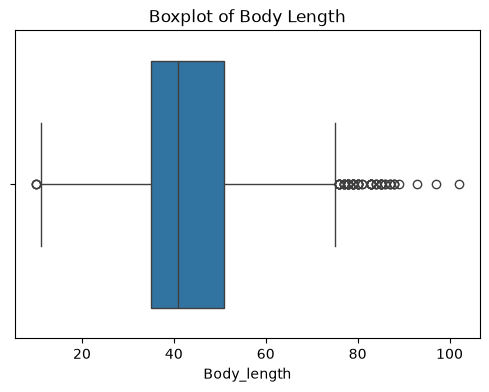

In [111]:
plt.figure(figsize=(6,4))
sns.boxplot(x=df['Body_length'])

plt.title('Boxplot of Body Length')
plt.show()

As the Box Plot of Body_length above exibits. There are a number of outlier values in the column. Suggesting some cats having significanlty longer bodies (>80), the the majorty which ranging around 40-50.

#### 4.2 Find and Display Outliers

In [112]:
Q1 = df['Body_length'].quantile(0.25)
Q3 = df['Body_length'].quantile(0.75)
IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = df[(df['Body_length'] < lower) | (df['Body_length'] > upper)]
outliers.head(15)

,Breed,Age_in_years,Age_in_months,Gender,Neutered_or_spayed,Body_length,Weight,Fur_colour_dominant,Fur_pattern,Eye_colour,Allowed_outdoor,Preferred_food,Owner_play_time_minutes,Sleep_time_hours,Country,Latitude,Longitude
342,NaN,2.08,25.00,female,True,76.0,6.31,black,solid,yellow,FALSE,wet,33.0,13.0,UK,53.480759,-2.242631
343,NaN,2.08,25.00,female,False,78.0,7.30,black,solid,yellow,FALSE,wet,14.0,13.0,UK,53.480759,-2.242631
346,Maine coon,2.17,26.00,male,False,85.0,9.00,red/cream,tabby,yellow,FALSE,wet,32.0,13.0,UK,53.480759,-2.242631
349,Maine coon,2.17,26.00,male,True,93.0,11.30,black,solid,yellow,FALSE,wet,29.0,13.0,UK,53.408371,-2.991573
356,Maine coon,2.33,28.00,female,True,80.0,6.90,black,solid,yellow,TRUE,wet,41.0,16.0,UK,52.486244,-1.890401
361,Maine coon,2.58,31.00,female,True,79.0,7.15,brown/chocolate,tabby,green,FALSE,dry,32.0,13.0,Germany,50.110924,8.682127
362,Maine coon,2.58,31.00,male,True,85.0,9.40,red/cream,tabby,green,FALSE,dry,44.0,13.0,Germany,52.520008,13.404954
364,Maine coon,2.58,31.00,male,True,85.0,9.60,black,solid,yellow,TRUE,dry,27.0,13.0,UK,53.480759,-2.242631
369,NaN,4.67,56.04,NaN,NaN,77.0,5.00,black,solid,yellow,FALSE,wet,28.0,17.0,UK,53.408371,-2.991573
370,Maine coon,2.83,34.00,male,True,83.0,10.80,red/cream,tabby,green,FALSE,dry,31.0,17.0,USA,42.358430,-71.059770


We can see from the dataframe above the first 15 rows that are outliers of the Body_length column. The values are approximatly 80 or more.

#### 4.3 Removing the Outliers

Outliers can effct statistical analysis of the data. Making the results skewed or biased, removing them is essential for an accurate EDA.

In [113]:
df_no_outliers = df[(df['Body_length'] >= lower) & (df['Body_length'] <= upper)]

print('df with outliers: ',df.shape)
print('df without outliers: ',df_no_outliers.shape)

df with outliers:  (1058, 17)
df without outliers:  (988, 17)


We can see from the shape of the datset that the size got reduced after removing the outlier rows

#### 4.4 Capping Outliers

Another method to handle outliers is by capping. Instead of removing the rows and risk much smaller dataset, capping handels the outliers differenty, by replacing those exteme values with the maximum limit in the IQR, which in turm manitain the dataset size.

In [114]:
lower_cap = df['Body_length'].quantile(0.05) # 5%
upper_cap = df['Body_length'].quantile(0.95) # 95%

df_capped = df.copy()
df_capped['Body_length'] = df_capped['Body_length'].clip(lower_cap, upper_cap)

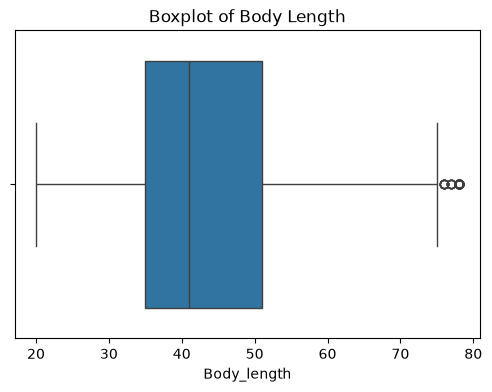

In [115]:
plt.figure(figsize=(6,4))
sns.boxplot(x=df_capped['Body_length'])

plt.title('Boxplot of Body Length')
plt.show()

The capping method successfully eliminated the outliers of the data by compressing the top 5% into a single maximum threshold (the 95th percentile). However, because this 95th percentile value is still higher than Upper limit of IQR, the boxplot continues to flag these points as outliers.

### 5. Data Normalization

> In this ection we normalize the data using two different methods: Z-Score and Min-Max.

In [116]:
df[['Body_length','Weight']].head()

,Body_length,Weight
0,19.0,2.0
1,19.0,2.5
2,20.0,2.8
3,21.0,3.0
4,21.0,3.0


#### 5.1 Z-Score Normalization

This method scales the data, so that every column mean is 0 and every standard deviation is around 1.

In [117]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
df_standardized = df[['Age_in_years', 'Age_in_months']].copy()

df_standardized[['Age_in_years', 'Age_in_months']] = scaler.fit_transform(df_standardized)

df_standardized.head(5)

,Age_in_years,Age_in_months
0,-1.313295,-1.313279
1,-1.288212,-1.287151
2,-1.234910,-1.234896
3,-1.234910,-1.234896
4,-1.234910,-1.234896


Since these values are less than zero, it means they are below the average of the column (\(<0\)). Specifically, a value like -1.53 indicates that the data point sits 1.53 standard deviations below the mean.

#### 5.2 Min-Max Normalization

Unlike Z-Score, Min-Max does not take the mean and standard deviation into consideration when scaling the data points. it normalizes the data by rescaling it into a range.

In [118]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()
df_scaled = df[['Body_length', 'Weight']].copy()

df_scaled[['Body_length', 'Weight']] = scaler.fit_transform(df_scaled)

df_scaled.head()

,Body_length,Weight
0,0.097826,0.004695
1,0.097826,0.006260
2,0.108696,0.007199
3,0.119565,0.007825
4,0.119565,0.007825


After normalization, the data values are compressed between 0 and 1, where the limits reflect the lowest and highest values in each column respectively.

### 6. Principal Component Analysis (PCA)

#### 6.1 Checking Dta Correlation

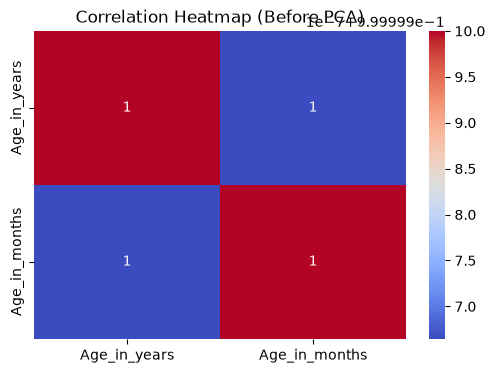

In [119]:
plt.figure(figsize=(6,4))
sns.heatmap(df_standardized[['Age_in_years','Age_in_months']].corr(), 
            annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap (Before PCA)")
plt.show()

From the correlation Heatmap  above we can see that there is perfect linear relationship between the Age_in_years and Age_in_months values. Which is expected since they represent the same feature using different units. Since we have a highy correlation value applying PCA would be very beneficial to the dataset in terms of reducing dimensionality.

#### 6.2 Applying PCA to The Dataset

In [120]:
from sklearn.decomposition import PCA

X = df_standardized[['Age_in_years', 'Age_in_months']]

pca = PCA(n_components=2)
principal_components = pca.fit_transform(X)

print("Explained Variance Ratio:", pca.explained_variance_ratio_)

Explained Variance Ratio: [9.99999832e-01 1.67741220e-07]


The output reveals that PC1 alone captures approximately 100% of the total variance in the age data. Meanwhile, PC2 captures virtually 0% of the variance. Together, both components account for exactly 100% of the information. With these exellent results we can say that applying PCA is effective, and dropping PC2 is not going to effect the data variance.

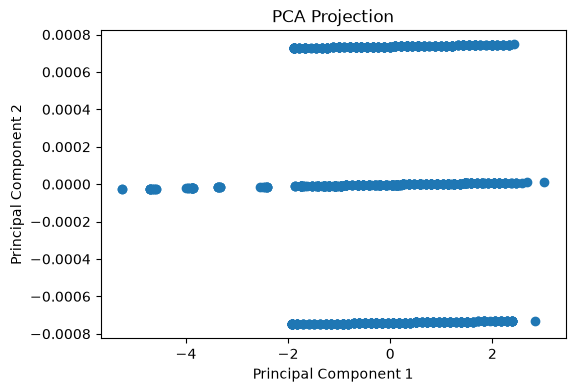

In [121]:
plt.figure(figsize=(6,4))
plt.scatter(principal_components[:,0], principal_components[:,1])
plt.title("PCA Projection")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.show()

We can see from the Scatter Plot above that most of the data speards horizontaly which means PC1 explains most of the data variance compared to PC2.

DataSet Link: https://www.kaggle.com/datasets/joannanplkrk/its-raining-cats?select=cat_breeds_dirty.csv